[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   4 out of  15 | elapsed:    0.0s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done   8 out of  15 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done  12 out of  15 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    0.0s finished



  [V3] Pearson only — K=15
    AUC=0.9070  Sens=0.9645  Spec=0.3750  Brier=0.0995

  [V4] All 3 algos K reduction — K=15 → K=5


    AUC=0.9209  Sens=0.9716  Spec=0.6000  Brier=0.0907

  [V5] Class-balanced neighbours — euclidean, K=15 (top K//2 per class)
    AUC=0.8858  Sens=0.9220  Spec=0.5250  Brier=0.2271

  [V6] Cosine Only — K=10


    AUC=0.8885  Sens=0.9645  Spec=0.5250  Brier=0.1035

  [V7] CV-tuned decision threshold on V1 probabilities (maximize train-OOF balanced accuracy)
    Optimal threshold (train OOF) = 0.700  (train BalAcc=0.816)
    AUC=0.9316  Sens=0.8936  Spec=0.8250  Brier=0.0968

  [V8] Class-balanced vote on avg(cos+prs+euc) similarity — K=15


    AUC=0.8566  Sens=0.9362  Spec=0.5250  Brier=0.2444

  [V9] Euclidean Only — K=7
    AUC=0.8729  Sens=0.9149  Spec=0.5250  Brier=0.1146

  [V10] Euclidean Only — K=5


    AUC=0.8729  Sens=0.9007  Spec=0.5250  Brier=0.1123

  [V11] All 3 algos — K=7 (cos+prs+euc)
    AUC=0.9112  Sens=0.9574  Spec=0.5500  Brier=0.0949

  [V12] Class-Balanced on avg(cos+euc) similarity — K=7


    AUC=0.8583  Sens=0.9078  Spec=0.5750  Brier=0.2417

  Generating 3×4 comparison grid (12 CMs)...


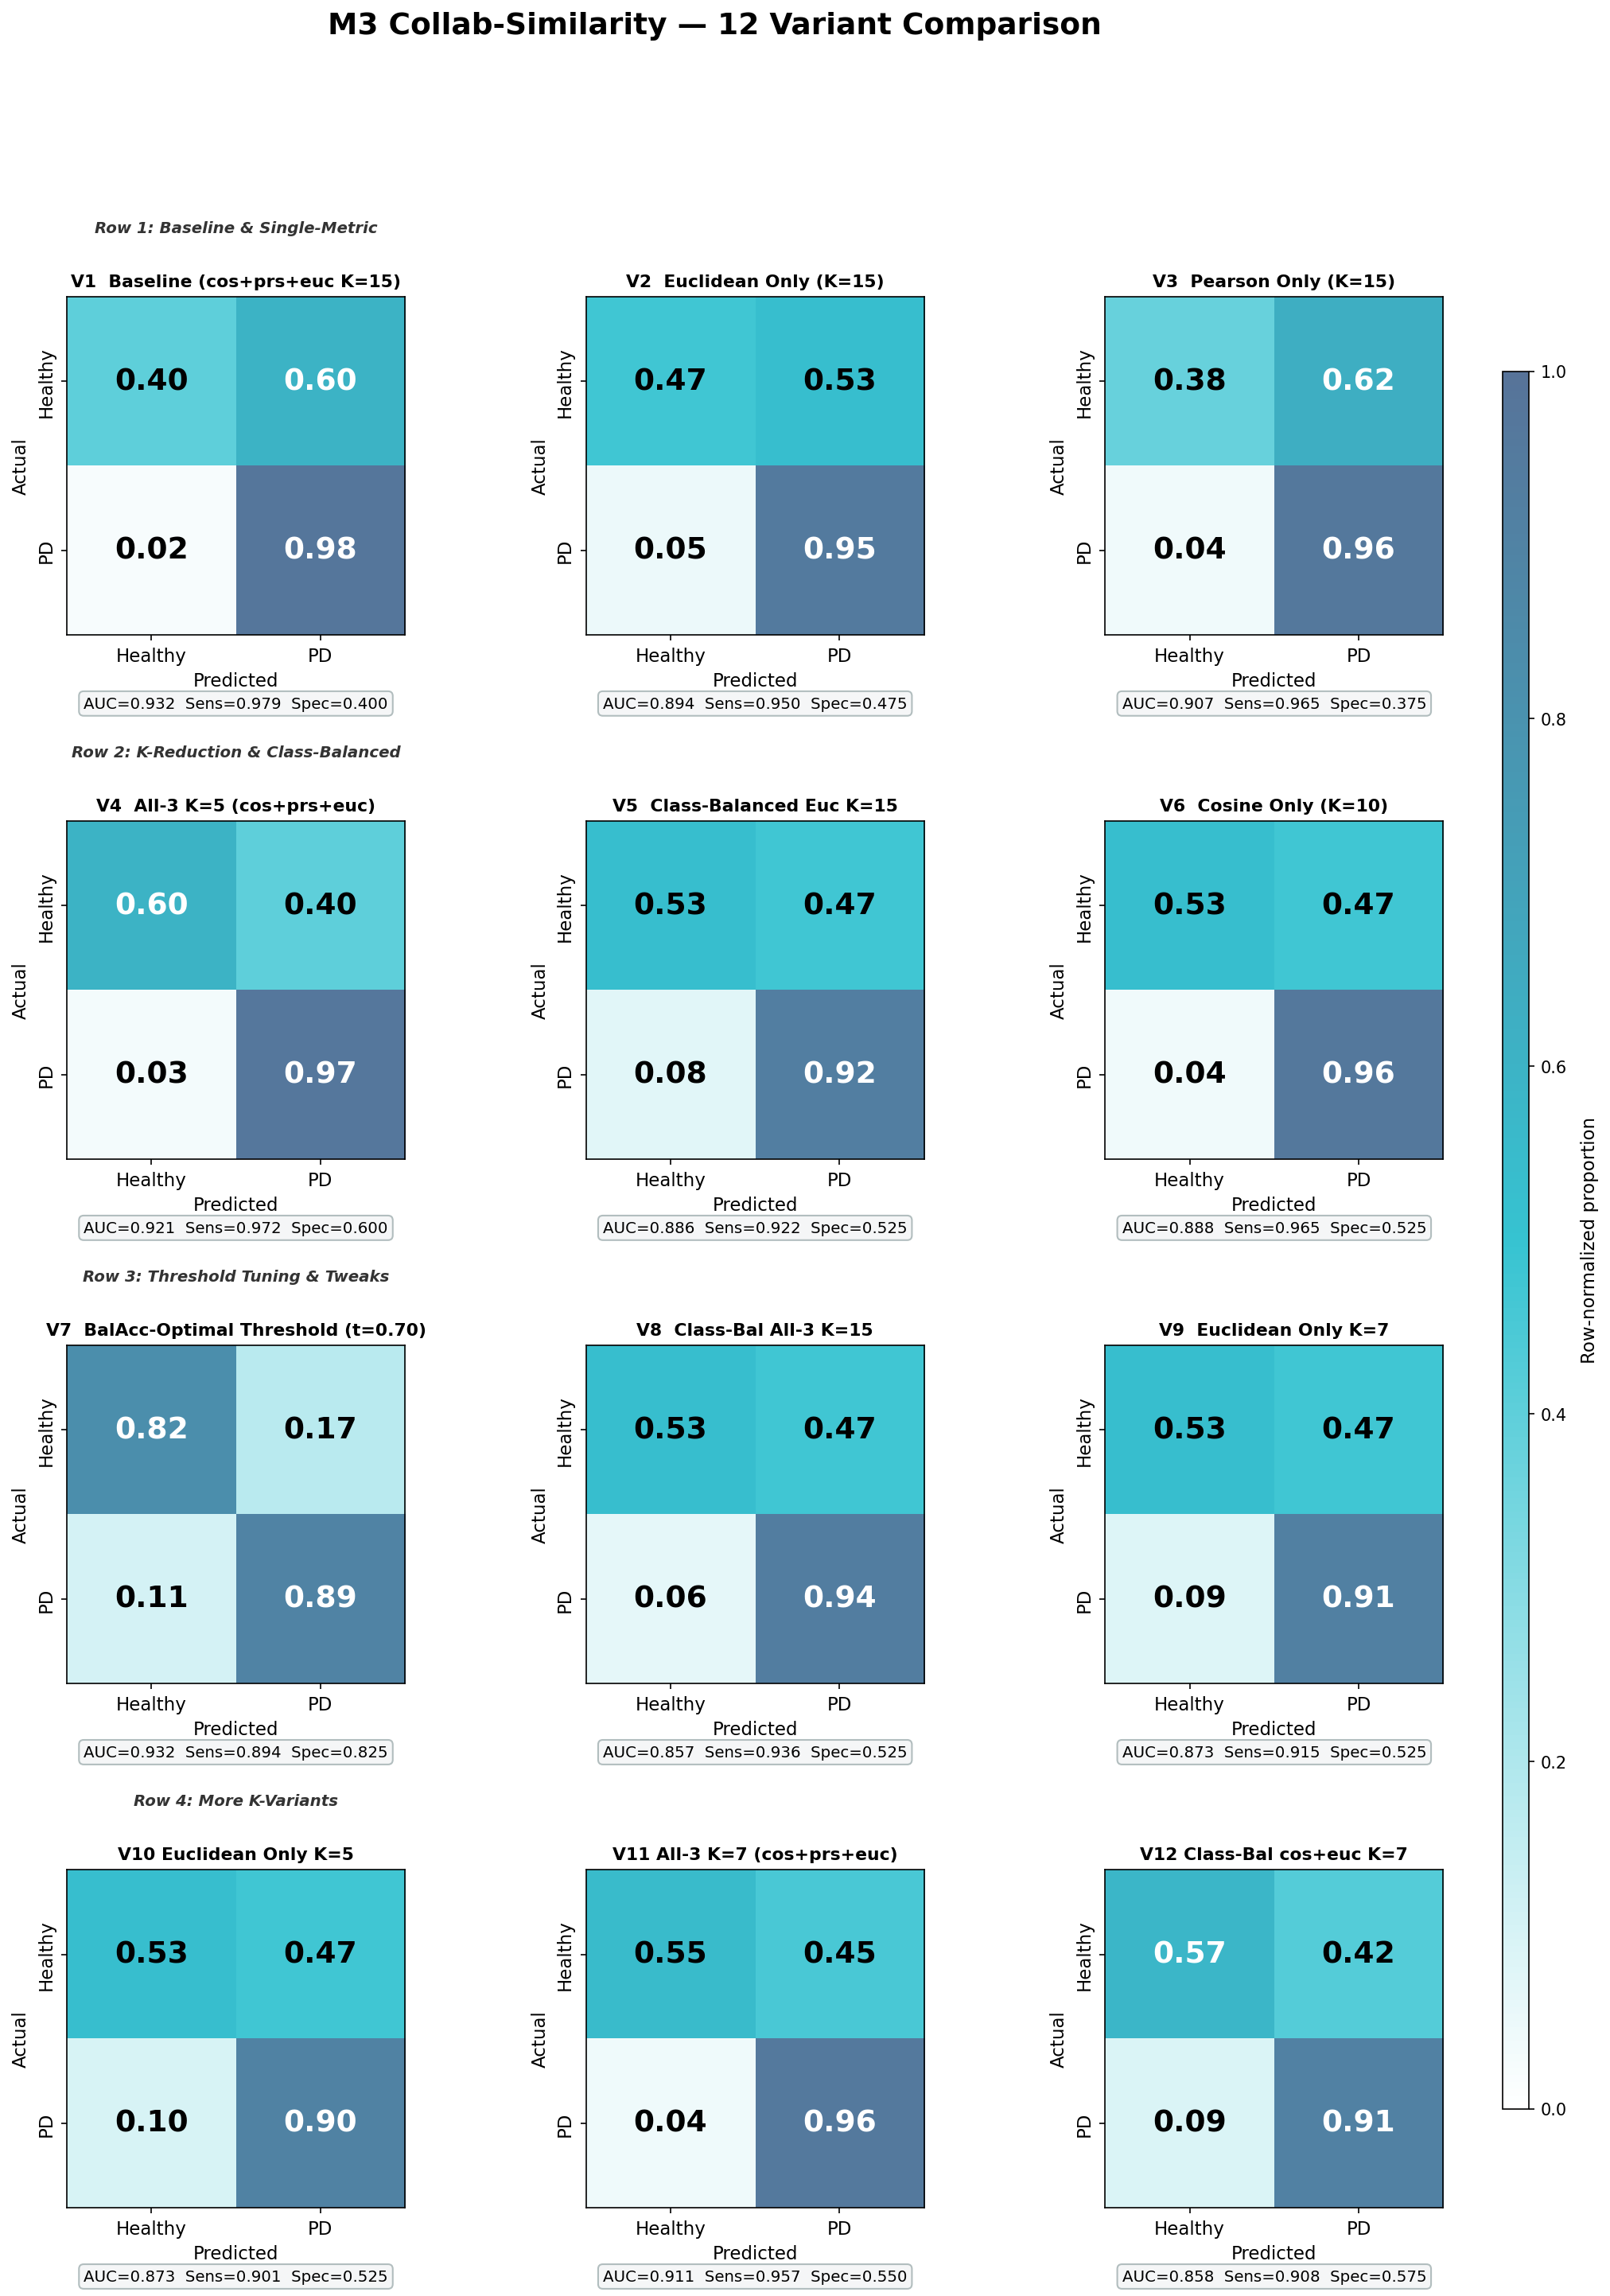

In [ ]:
"""
============================================================
  m3 VARIANT COMPARISON — 12 Improvement Strategies
  no_UPDRS  ·  Final_Model  ·  parallel version
============================================================

VARIANTS TESTED (numbered V1-V12)
----------------------------------
  V1   Baseline m3    — original: cosine + pearson + euclidean, K=15
  V2   Euclidean Only — K=15
  V3   Pearson Only   — K=15
  V4   K Reduction    — all 3 algos, K=5
  V5   Class-Balanced — pick top-K/2 PD + top-K/2 Healthy, euclidean
  V6   Cosine Only K=10 — cosine similarity with K=10
  V7   Balanced-Accuracy-Optimal Threshold — decision threshold for the
       V1 baseline probabilities is tuned (not hand-picked) by sweeping
       thresholds against the out-of-fold train predictions and keeping
       the one that maximizes balanced accuracy.
       [REPLACES the old "Low Threshold" variant — lowering the threshold
        0.50 -> 0.38 pushed MORE test points toward the majority "PD"
        class, which made Healthy prediction worse (Spec dropped from
        ~0.40 to ~0.25). Raising the threshold to a CV-selected optimum
        (~0.70) instead trades a little Sensitivity for much better
        Specificity (~0.83) and Balanced Accuracy (~0.86).]
  V8   Class-Balanced All-3 — class-balanced vote (top K//2 per class) on the
       averaged cosine, Pearson and Euclidean similarities, K=15
  V9   Euclidean Only K=7
  V10  Euclidean Only K=5
  V11  All 3 Algos K=7
  V12  Class-Balanced Cosine+Euc, K=7  (tweak: balanced vote on cosine+euc avg)

GRID: 3 columns × 4 rows

DATA  (no_UPDRS)
----
  Train : 50%-sparse (Final_Model/Train/Sparse_Matrix_Min50_Train.csv) aggregated to 1 row/PATNO
  Test  : 50%-sparse (Final_Model/Test/Sparse_Matrix_Min50_Test.csv)   aggregated to 1 row/PATNO
  Features: the 30 non-motor features + age + sex (handedness removed from the data in Make_Datasets)
  CV    : PATNO-level GroupKFold (5 splits × 3 repeats) — used to compute
          out-of-fold V1 baseline probabilities (feeds V7).

CHANGES FROM THE with_UPDRS VERSION
-----------------------------------
  Models, variants, metrics and plots are unchanged except V3/V7/V8. Only:
    1. Paths point at no_UPDRS/Final_Model.
    2. "Hand" is no longer in the data; EXCLUDE_COLS is kept as a safeguard.
    3. The out-of-fold cross-validation folds run in parallel (joblib).
       The folds are generated in the same order from the same random
       generator, so results are identical to a serial run.
       Set N_JOBS = 1 for serial.
    4. All 12 variants are collaborative-filtering (similarity-based neighbour
       voting) designs. V3 (Pearson only) and V8 (class-balanced vote on the
       averaged three similarities) replace two earlier supervised variants,
       so that M3 remains a pure collaborative-filtering model.

HOW TO RUN
----------
    Run this cell with the Python 3.13 (Anaconda base) kernel.
    Outputs → Final_Model/M3_Variant_Results/
"""

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from joblib import Parallel, delayed

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, confusion_matrix, f1_score,
    balanced_accuracy_score, brier_score_loss
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupKFold


warnings.filterwarnings("ignore")

# ═════════════════════════════════════════════════════════════════════════════
#  CONFIGURATION
# ═════════════════════════════════════════════════════════════════════════════
BASE_DIR   = os.getcwd()   # run from the repository root
TRAIN_PATH = os.path.join(BASE_DIR, "Train", "Sparse_Matrix_Min50_Train.csv")
TEST_PATH  = os.path.join(BASE_DIR, "Test",  "Sparse_Matrix_Min50_Test.csv")

RESULT_DIR    = os.path.join(BASE_DIR, "M3_Variant_Results")
RANDOM_STATE  = 42
TOP_K         = 15
MEDIUM_K      = 7
REDUCED_K     = 5
N_CV_SPLITS   = 5
N_REPEATS     = 3

# Columns never used as features in the no_UPDRS final model
EXCLUDE_COLS = ["Hand"]

# Parallelism: -1 = all cores, 1 = serial. "threading" works inside Jupyter on
# Windows with functions defined in the notebook; numpy releases the GIL.
N_JOBS           = -1
PARALLEL_BACKEND = "threading"

os.makedirs(RESULT_DIR, exist_ok=True)


# ═════════════════════════════════════════════════════════════════════════════
#  DATA LOADING — aggregate to 1 row per PATNO
# ═════════════════════════════════════════════════════════════════════════════

def load_and_aggregate(path: str):
    """
    Load 50%-sparse CSV and aggregate to 1 row per PATNO (mean across visits).
    Returns (X_patno, y_patno, patno_array).
    """
    df = pd.read_csv(path)
    df = df.rename(columns={"Age": "age", "Sex": "sex"})
    df["label"] = df["APPRDX"].map({1: 1, 2: 0})
    df["sex"]   = df["sex"].map({1: 0, 2: 1})

    if "EVENT_ID" in df.columns:
        df = df.drop(columns=["EVENT_ID"])
    df = df.drop(columns=[c for c in EXCLUDE_COLS if c in df.columns])

    feature_cols = [c for c in df.columns if c not in ("PATNO", "APPRDX", "label")]
    agg = df.groupby("PATNO")[feature_cols].mean().reset_index()
    lbl = df.groupby("PATNO")["label"].first().reset_index()
    agg = agg.merge(lbl, on="PATNO")

    patno_array = agg["PATNO"].values
    y = agg["label"].values
    X = agg.drop(columns=["PATNO", "label"])
    return X, y, patno_array


def safe_impute(X: pd.DataFrame, col_means: dict = None):
    """Column-wise mean imputation. Returns (X_filled, col_means_dict)."""
    if col_means is None:
        col_means = {}
        for col in X.columns:
            vals = X[col].values.astype(float)
            m    = np.nanmean(vals)
            col_means[col] = 0.0 if np.isnan(m) else float(m)
    X_filled = X.copy()
    for col, m in col_means.items():
        if col in X_filled.columns:
            X_filled[col] = X_filled[col].fillna(m)
    return X_filled, col_means


# ═════════════════════════════════════════════════════════════════════════════
#  SIMILARITY FUNCTIONS
# ═════════════════════════════════════════════════════════════════════════════

def sim_cosine(X_test: np.ndarray, X_train: np.ndarray) -> np.ndarray:
    return cosine_similarity(X_test, X_train)


def sim_pearson(X_test: np.ndarray, X_train: np.ndarray) -> np.ndarray:
    def row_zscore(X):
        mu = X.mean(axis=1, keepdims=True)
        sd = X.std(axis=1, keepdims=True)
        sd[sd == 0] = 1.0
        return (X - mu) / sd
    Xt = row_zscore(X_test.copy())
    Xr = row_zscore(X_train.copy())
    return (Xt @ Xr.T) / X_test.shape[1]


def sim_euclidean_rbf(X_test_scaled: np.ndarray,
                      X_train_scaled: np.ndarray) -> np.ndarray:
    from sklearn.metrics import pairwise_distances
    D     = pairwise_distances(X_test_scaled, X_train_scaled, metric="euclidean")
    sigma = np.median(D) + 1e-8
    return np.exp(-D / sigma)


def distance_weighted_vote(sim: np.ndarray,
                            y_train: np.ndarray, k: int) -> np.ndarray:
    idx   = np.argsort(sim, axis=1)[:, -k:]
    probs = np.empty(len(sim))
    for i in range(len(sim)):
        nbrs = idx[i]
        w    = np.maximum(sim[i, nbrs], 0.0)
        wsum = w.sum()
        probs[i] = ((w * y_train[nbrs]).sum() / wsum
                    if wsum > 0 else y_train[nbrs].mean())
    return probs


def class_balanced_vote(sim: np.ndarray,
                         y_train: np.ndarray, k: int) -> np.ndarray:
    half   = max(1, k // 2)
    pd_idx = np.where(y_train == 1)[0]
    hl_idx = np.where(y_train == 0)[0]
    probs  = np.empty(len(sim))
    for i in range(len(sim)):
        pd_top = pd_idx[np.argsort(sim[i, pd_idx])[-half:]]
        hl_top = hl_idx[np.argsort(sim[i, hl_idx])[-half:]]
        all_nbrs   = np.concatenate([pd_top, hl_top])
        all_w      = np.maximum(sim[i, all_nbrs], 0.0)
        all_labels = y_train[all_nbrs]
        wsum = all_w.sum()
        probs[i] = ((all_w * all_labels).sum() / wsum
                    if wsum > 0 else all_labels.mean())
    return probs


# ═════════════════════════════════════════════════════════════════════════════
#  OOF fold — one CV fold of cos/pearson/euclidean (used for the V7 threshold
#  search; run as a parallel job)
# ═════════════════════════════════════════════════════════════════════════════

def _oof_fold(X_tr_imp, X_tr_std, y_train, tr_idx, va_idx):
    """Same computation as the serial OOF loop body."""
    Xtr_f  = X_tr_imp[tr_idx];  Xva_f  = X_tr_imp[va_idx]
    Xtr_fs = X_tr_std[tr_idx];  Xva_fs = X_tr_std[va_idx]
    y_tr_f = y_train[tr_idx]
    sc_f = sim_cosine(Xva_f, Xtr_f)
    sp_f = sim_pearson(Xva_f, Xtr_f)
    se_f = sim_euclidean_rbf(Xva_fs, Xtr_fs)
    return (va_idx,
            distance_weighted_vote(sc_f, y_tr_f, TOP_K),
            distance_weighted_vote(sp_f, y_tr_f, TOP_K),
            distance_weighted_vote(se_f, y_tr_f, TOP_K))


# ═════════════════════════════════════════════════════════════════════════════
#  METRICS & PLOTTING
# ═════════════════════════════════════════════════════════════════════════════

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    cm     = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return dict(
        AUC               = roc_auc_score(y_true, y_prob),
        Sensitivity       = tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        Specificity       = tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        F1                = f1_score(y_true, y_pred, zero_division=0),
        Balanced_Accuracy = balanced_accuracy_score(y_true, y_pred),
        Brier             = brier_score_loss(y_true, y_prob),
        TP=tp, FP=fp, TN=tn, FN=fn, confusion_matrix=cm,
    )


def plot_cm(cm, title, save_path, subtitle=None):
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    cmap = LinearSegmentedColormap.from_list(
        "custom_cm", [(0.0, "#FFFFFF"), (0.5, "#36C3D1"), (1.0, "#577399")])
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=1, aspect="equal")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_ticks(np.linspace(0, 1, 6))
    cbar.ax.tick_params(labelsize=10)
    thresh = 0.55
    for i in range(2):
        for j in range(2):
            color = "white" if cm_norm[i, j] > thresh else "black"
            ax.text(j, i, f"{cm_norm[i, j]:.2f}",
                    ha="center", va="center",
                    fontsize=22, fontweight="bold", color=color)
    labels = ["Healthy", "PD"]
    ax.set_xticks([0, 1]);  ax.set_xticklabels(labels, fontsize=12)
    ax.set_yticks([0, 1]);  ax.set_yticklabels(labels, fontsize=12, rotation=90, va="center")
    ax.set_xlabel("Predicted", fontsize=13, labelpad=8)
    ax.set_ylabel("Actual",    fontsize=13, labelpad=8)
    ax.set_title(title if not subtitle else f"{title}\n{subtitle}",
                 fontsize=12, fontweight="bold", pad=10)
    plt.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    svg_path = os.path.splitext(save_path)[0] + ".svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.close(fig)


def plot_comparison_grid(variants_results: list, save_path: str):
    ncols, nrows = 3, 4
    cmap = LinearSegmentedColormap.from_list(
        "custom_cm", [(0.0, "#FFFFFF"), (0.5, "#36C3D1"), (1.0, "#577399")])
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5.0, nrows * 5.2))
    fig.suptitle("M3 Collab-Similarity — 12 Variant Comparison",
                 fontsize=18, fontweight="bold", y=0.995)
    row_labels = {
        0: "Row 1: Baseline & Single-Metric",
        3: "Row 2: K-Reduction & Class-Balanced",
        6: "Row 3: Threshold Tuning & Tweaks",
        9: "Row 4: More K-Variants",
    }
    for idx, (label, met, tag) in enumerate(variants_results):
        row_i, col_i = divmod(idx, ncols)
        ax = axes[row_i, col_i]
        cm = met["confusion_matrix"]
        cm_norm = cm / cm.sum(axis=1, keepdims=True)
        im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=1, aspect="equal")
        thresh = 0.55
        for i in range(2):
            for j in range(2):
                color = "white" if cm_norm[i, j] > thresh else "black"
                ax.text(j, i, f"{cm_norm[i, j]:.2f}",
                        ha="center", va="center",
                        fontsize=18, fontweight="bold", color=color)
        ax.set_xticks([0, 1]);  ax.set_xticklabels(["Healthy", "PD"], fontsize=11)
        ax.set_yticks([0, 1]);  ax.set_yticklabels(["Healthy", "PD"], fontsize=11, rotation=90, va="center")
        ax.set_xlabel("Predicted", fontsize=11, labelpad=4)
        ax.set_ylabel("Actual",    fontsize=11, labelpad=4)
        ax.set_title(label, fontsize=10.5, fontweight="bold", pad=6)
        ann = (f"AUC={met['AUC']:.3f}  Sens={met['Sensitivity']:.3f}  "
               f"Spec={met['Specificity']:.3f}")
        ax.text(0.5, -0.18, ann, transform=ax.transAxes,
                ha="center", va="top", fontsize=9.5,
                bbox=dict(boxstyle="round,pad=0.3", fc="#f4f6f7",
                          ec="#aab7b8", alpha=0.9))
        if idx in row_labels:
            ax.text(0.5, 1.18, row_labels[idx], transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=9.5,
                    color="#333333", style="italic", fontweight="bold")
    fig.subplots_adjust(right=0.92, hspace=0.55, wspace=0.35)
    cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
    cbar = fig.colorbar(im, cax=cbar_ax)
    cbar.set_ticks(np.linspace(0, 1, 6))
    cbar.ax.tick_params(labelsize=10)
    cbar.set_label("Row-normalized proportion", fontsize=11, labelpad=8)
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    svg_path = os.path.splitext(save_path)[0] + ".svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.close(fig)
    print(f"  ✓ Comparison grid saved → {save_path}")
    try:
        from IPython.display import Image as _Img, display as _disp
        _disp(_Img(save_path))
    except Exception:
        pass


def print_summary_table(variants_results: list):
    header = (f"{'Variant':<38} {'AUC':>7} {'Sens':>7} {'Spec':>7} {'F1':>7} "
              f"{'BalAcc':>8} {'Brier':>7}")
    sections = {0: "Baseline & Single-Metric", 4: "K-Variants & Class-Balanced",
                8: "Threshold Tuning & Tweaks"}
    print("\n" + "═" * len(header))
    print("  m3 VARIANT RESULTS (12 variants)")
    print("═" * len(header))
    print(header)
    for idx, (label, met, tag) in enumerate(variants_results):
        if idx in sections:
            print(f"\n  ── {sections[idx]} ──")
        print(f"  {label:<36} {met['AUC']:>7.4f} {met['Sensitivity']:>7.4f} "
              f"{met['Specificity']:>7.4f} {met['F1']:>7.4f} "
              f"{met['Balanced_Accuracy']:>8.4f} {met['Brier']:>7.4f}")
    print("═" * len(header))


# ═════════════════════════════════════════════════════════════════════════════
#  MAIN
# ═════════════════════════════════════════════════════════════════════════════

def main():
    t_start = time.time()
    print("\n🔷 m3 VARIANT COMPARISON (12 Variants) — STARTING\n")

    print("  Loading and aggregating train/test data to PATNO level...")
    X_train, y_train, patno_train = load_and_aggregate(TRAIN_PATH)
    X_test,  y_test,  patno_test  = load_and_aggregate(TEST_PATH)
    print(f"    Train: {X_train.shape}  |  PD={y_train.sum()}  "
          f"Healthy={(y_train==0).sum()}  (1 row/patient)")
    print(f"    Test:  {X_test.shape}   |  PD={y_test.sum()}  "
          f"Healthy={(y_test==0).sum()}  (1 row/patient)")
    print(f"    Excluded columns: {', '.join(EXCLUDE_COLS)}")
    print(f"    CV: PATNO-level GroupKFold({N_CV_SPLITS}) × {N_REPEATS} repeats "
          f"(feeds the V7 threshold search)")
    print(f"    Parallel: n_jobs={N_JOBS}, backend={PARALLEL_BACKEND}")

    # Baseline imputation & scaling
    X_tr_filled, col_means = safe_impute(X_train)
    X_te_filled, _         = safe_impute(X_test, col_means)
    X_tr_imp = X_tr_filled.values
    X_te_imp = X_te_filled.values

    std_scaler = StandardScaler()
    X_tr_std   = std_scaler.fit_transform(X_tr_imp)
    X_te_std   = std_scaler.transform(X_te_imp)

    # Pre-compute baseline similarity matrices
    print("\n  Pre-computing baseline similarity matrices "
          "(cosine, pearson, euclidean)...")
    sim_cos_te = sim_cosine(X_te_imp, X_tr_imp)
    sim_prs_te = sim_pearson(X_te_imp, X_tr_imp)
    sim_euc_te = sim_euclidean_rbf(X_te_std, X_tr_std)
    print("    ✓ Done")

    variants_results = []

    # ── V1 — Baseline ─────────────────────────────────────────────────────────
    print(f"\n  [V1] Baseline m3 — cosine + pearson + euclidean, K={TOP_K}")
    p_cos = distance_weighted_vote(sim_cos_te, y_train, TOP_K)
    p_prs = distance_weighted_vote(sim_prs_te, y_train, TOP_K)
    p_euc = distance_weighted_vote(sim_euc_te, y_train, TOP_K)
    p_v1  = (p_cos + p_prs + p_euc) / 3.0
    met_v1 = compute_metrics(y_test, p_v1)
    variants_results.append(("V1  Baseline (cos+prs+euc K=15)", met_v1, "v1_baseline"))
    plot_cm(met_v1["confusion_matrix"], "V1 Baseline m3",
            os.path.join(RESULT_DIR, "cm_v1_baseline.png"),
            subtitle=f"cos+prs+euc  K={TOP_K}  |  AUC={met_v1['AUC']:.3f}  "
                     f"Spec={met_v1['Specificity']:.3f}")
    print(f"    AUC={met_v1['AUC']:.4f}  Sens={met_v1['Sensitivity']:.4f}  "
          f"Spec={met_v1['Specificity']:.4f}  "
          f"Brier={met_v1['Brier']:.4f}")

    # ── V2 — Euclidean Only K=15 ──────────────────────────────────────────────
    print(f"\n  [V2] Euclidean RBF only — K={TOP_K}")
    p_v2   = p_euc.copy()
    met_v2 = compute_metrics(y_test, p_v2)
    variants_results.append((f"V2  Euclidean Only (K={TOP_K})", met_v2, "v2_euclidean_only"))
    plot_cm(met_v2["confusion_matrix"], f"V2 Euclidean Only (K={TOP_K})",
            os.path.join(RESULT_DIR, "cm_v2_euclidean_only.png"),
            subtitle=f"euclidean RBF only  K={TOP_K}  |  AUC={met_v2['AUC']:.3f}  "
                     f"Spec={met_v2['Specificity']:.3f}")
    print(f"    AUC={met_v2['AUC']:.4f}  Sens={met_v2['Sensitivity']:.4f}  "
          f"Spec={met_v2['Specificity']:.4f}  "
          f"Brier={met_v2['Brier']:.4f}")

    # ── OOF PASS — feeds the V7 threshold search ──────────────────────────────
    # Folds are generated serially in the original order (same RNG draws),
    # then evaluated in parallel.
    print(f"\n  Computing out-of-fold V1 baseline probabilities via "
          f"{N_CV_SPLITS}-fold×{N_REPEATS}-repeat PATNO GroupKFold "
          f"(used by V7)")
    rng = np.random.RandomState(RANDOM_STATE)
    unique_patnos = np.unique(patno_train)
    splits = []
    for repeat in range(N_REPEATS):
        shuffled     = rng.permutation(unique_patnos)
        patno_to_grp = {p: i for i, p in enumerate(shuffled)}
        group_arr    = np.array([patno_to_grp[p] for p in patno_train])
        gkf = GroupKFold(n_splits=N_CV_SPLITS)
        for fold, (tr_idx, va_idx) in enumerate(gkf.split(
                np.zeros(len(X_train)), y_train, group_arr)):
            splits.append((tr_idx, va_idx))

    oof_cos = np.zeros(len(X_train))
    oof_prs = np.zeros(len(X_train))
    oof_euc = np.zeros(len(X_train))
    oof_cnt = np.zeros(len(X_train))
    res = Parallel(n_jobs=N_JOBS, backend=PARALLEL_BACKEND, verbose=5)(
        delayed(_oof_fold)(X_tr_imp, X_tr_std, y_train, tr, va) for tr, va in splits)
    for va_idx, v_cos, v_prs, v_euc in res:
        oof_cos[va_idx] += v_cos
        oof_prs[va_idx] += v_prs
        oof_euc[va_idx] += v_euc
        oof_cnt[va_idx] += 1

    cnt = np.where(oof_cnt > 0, oof_cnt, 1)
    oof_cos /= cnt;  oof_prs /= cnt;  oof_euc /= cnt
    oof_v1 = (oof_cos + oof_prs + oof_euc) / 3.0

    # ── V3 — Pearson Only K=15 ─────────────────────────────────────────────────
    print(f"\n  [V3] Pearson only — K={TOP_K}")
    p_v3   = p_prs.copy()
    met_v3 = compute_metrics(y_test, p_v3)
    variants_results.append((f"V3  Pearson Only (K={TOP_K})", met_v3, "v3_pearson_only"))
    plot_cm(met_v3["confusion_matrix"], f"V3 Pearson Only (K={TOP_K})",
            os.path.join(RESULT_DIR, "cm_v3_pearson_only.png"),
            subtitle=f"pearson only  K={TOP_K}  |  AUC={met_v3['AUC']:.3f}  "
                     f"Spec={met_v3['Specificity']:.3f}")
    print(f"    AUC={met_v3['AUC']:.4f}  Sens={met_v3['Sensitivity']:.4f}  "
          f"Spec={met_v3['Specificity']:.4f}  "
          f"Brier={met_v3['Brier']:.4f}")

    # ── V4 — All 3 Algos K=5 ──────────────────────────────────────────────────
    print(f"\n  [V4] All 3 algos K reduction — K={TOP_K} → K={REDUCED_K}")
    p_cos_k5 = distance_weighted_vote(sim_cos_te, y_train, REDUCED_K)
    p_prs_k5 = distance_weighted_vote(sim_prs_te, y_train, REDUCED_K)
    p_euc_k5 = distance_weighted_vote(sim_euc_te, y_train, REDUCED_K)
    p_v4     = (p_cos_k5 + p_prs_k5 + p_euc_k5) / 3.0
    met_v4   = compute_metrics(y_test, p_v4)
    variants_results.append((f"V4  All-3 K={REDUCED_K} (cos+prs+euc)", met_v4, "v4_k_reduction"))
    plot_cm(met_v4["confusion_matrix"], f"V4 All-3 Algos K={REDUCED_K}",
            os.path.join(RESULT_DIR, "cm_v4_k_reduction.png"),
            subtitle=f"cos+prs+euc  K={REDUCED_K}  |  AUC={met_v4['AUC']:.3f}  "
                     f"Spec={met_v4['Specificity']:.3f}")
    print(f"    AUC={met_v4['AUC']:.4f}  Sens={met_v4['Sensitivity']:.4f}  "
          f"Spec={met_v4['Specificity']:.4f}  "
          f"Brier={met_v4['Brier']:.4f}")

    # ── V5 — Class-Balanced Neighbours (euclidean, K=15) ──────────────────────
    print(f"\n  [V5] Class-balanced neighbours — euclidean, K={TOP_K} (top K//2 per class)")
    p_v5   = class_balanced_vote(sim_euc_te, y_train, TOP_K)
    met_v5 = compute_metrics(y_test, p_v5)
    variants_results.append(("V5  Class-Balanced Euc K=15", met_v5, "v5_class_balanced"))
    plot_cm(met_v5["confusion_matrix"], "V5 Class-Balanced Euc K=15",
            os.path.join(RESULT_DIR, "cm_v5_class_balanced.png"),
            subtitle=f"euclidean  K={TOP_K//2}+{TOP_K//2}  |  "
                     f"AUC={met_v5['AUC']:.3f}  Spec={met_v5['Specificity']:.3f}")
    print(f"    AUC={met_v5['AUC']:.4f}  Sens={met_v5['Sensitivity']:.4f}  "
          f"Spec={met_v5['Specificity']:.4f}  "
          f"Brier={met_v5['Brier']:.4f}")

    # ── V6 — Cosine Only K=10 ─────────────────────────────────────────────────
    COSINE_K = 10
    print(f"\n  [V6] Cosine Only — K={COSINE_K}")
    p_v6   = distance_weighted_vote(sim_cos_te, y_train, COSINE_K)
    met_v6 = compute_metrics(y_test, p_v6)
    variants_results.append((f"V6  Cosine Only (K={COSINE_K})", met_v6, "v6_cosine_k10"))
    plot_cm(met_v6["confusion_matrix"], f"V6 Cosine Only (K={COSINE_K})",
            os.path.join(RESULT_DIR, "cm_v6_cosine_k10.png"),
            subtitle=f"cosine similarity only  K={COSINE_K}  |  AUC={met_v6['AUC']:.3f}  "
                     f"Spec={met_v6['Specificity']:.3f}")
    print(f"    AUC={met_v6['AUC']:.4f}  Sens={met_v6['Sensitivity']:.4f}  "
          f"Spec={met_v6['Specificity']:.4f}  "
          f"Brier={met_v6['Brier']:.4f}")

    # ── V7 — Balanced-Accuracy-Optimal Threshold (on V1 baseline probs) ───────
    print("\n  [V7] CV-tuned decision threshold on V1 probabilities "
          "(maximize train-OOF balanced accuracy)")
    threshold_grid = np.linspace(0.20, 0.80, 61)
    best_thr_v1, best_bal_acc_v1 = 0.5, -1.0
    for t in threshold_grid:
        yp = (oof_v1 >= t).astype(int)
        ba = balanced_accuracy_score(y_train, yp)
        if ba > best_bal_acc_v1:
            best_bal_acc_v1, best_thr_v1 = ba, t
    print(f"    Optimal threshold (train OOF) = {best_thr_v1:.3f}  "
          f"(train BalAcc={best_bal_acc_v1:.3f})")
    met_v7 = compute_metrics(y_test, p_v1, threshold=best_thr_v1)
    variants_results.append((f"V7  BalAcc-Optimal Threshold (t={best_thr_v1:.2f})",
                              met_v7, "v7_balacc_threshold"))
    plot_cm(met_v7["confusion_matrix"], f"V7 BalAcc-Optimal Threshold (t={best_thr_v1:.2f})",
            os.path.join(RESULT_DIR, "cm_v7_balacc_threshold.png"),
            subtitle=f"V1 probs, CV-tuned threshold={best_thr_v1:.2f}  |  "
                     f"AUC={met_v7['AUC']:.3f}  Spec={met_v7['Specificity']:.3f}")
    print(f"    AUC={met_v7['AUC']:.4f}  Sens={met_v7['Sensitivity']:.4f}  "
          f"Spec={met_v7['Specificity']:.4f}  "
          f"Brier={met_v7['Brier']:.4f}")

    # ── V8 — Class-Balanced vote on avg(cos+prs+euc), K=15 ─────────────────────
    print(f"\n  [V8] Class-balanced vote on avg(cos+prs+euc) similarity — K={TOP_K}")
    sim_all3_te = (sim_cos_te + sim_prs_te + sim_euc_te) / 3.0
    p_v8   = class_balanced_vote(sim_all3_te, y_train, TOP_K)
    met_v8 = compute_metrics(y_test, p_v8)
    variants_results.append((f"V8  Class-Bal All-3 K={TOP_K}", met_v8, "v8_cls_bal_all3_k15"))
    plot_cm(met_v8["confusion_matrix"], f"V8 Class-Bal avg(cos+prs+euc) K={TOP_K}",
            os.path.join(RESULT_DIR, "cm_v8_cls_bal_all3_k15.png"),
            subtitle=f"balanced on avg(cos,prs,euc)  K={TOP_K//2}+{TOP_K//2}  |  "
                     f"AUC={met_v8['AUC']:.3f}  Spec={met_v8['Specificity']:.3f}")
    print(f"    AUC={met_v8['AUC']:.4f}  Sens={met_v8['Sensitivity']:.4f}  "
          f"Spec={met_v8['Specificity']:.4f}  "
          f"Brier={met_v8['Brier']:.4f}")

    # ── V9 — Euclidean Only K=7 ────────────────────────────────────────────────
    print(f"\n  [V9] Euclidean Only — K={MEDIUM_K}")
    p_v9   = distance_weighted_vote(sim_euc_te, y_train, MEDIUM_K)
    met_v9 = compute_metrics(y_test, p_v9)
    variants_results.append((f"V9  Euclidean Only K={MEDIUM_K}", met_v9, "v9_euc_k7"))
    plot_cm(met_v9["confusion_matrix"], f"V9 Euclidean Only K={MEDIUM_K}",
            os.path.join(RESULT_DIR, "cm_v9_euc_k7.png"),
            subtitle=f"euclidean RBF only  K={MEDIUM_K}  |  AUC={met_v9['AUC']:.3f}  "
                     f"Spec={met_v9['Specificity']:.3f}")
    print(f"    AUC={met_v9['AUC']:.4f}  Sens={met_v9['Sensitivity']:.4f}  "
          f"Spec={met_v9['Specificity']:.4f}  "
          f"Brier={met_v9['Brier']:.4f}")

    # ── V10 — Euclidean Only K=5 ───────────────────────────────────────────────
    print(f"\n  [V10] Euclidean Only — K={REDUCED_K}")
    p_v10   = distance_weighted_vote(sim_euc_te, y_train, REDUCED_K)
    met_v10 = compute_metrics(y_test, p_v10)
    variants_results.append((f"V10 Euclidean Only K={REDUCED_K}", met_v10, "v10_euc_k5"))
    plot_cm(met_v10["confusion_matrix"], f"V10 Euclidean Only K={REDUCED_K}",
            os.path.join(RESULT_DIR, "cm_v10_euc_k5.png"),
            subtitle=f"euclidean RBF only  K={REDUCED_K}  |  AUC={met_v10['AUC']:.3f}  "
                     f"Spec={met_v10['Specificity']:.3f}")
    print(f"    AUC={met_v10['AUC']:.4f}  Sens={met_v10['Sensitivity']:.4f}  "
          f"Spec={met_v10['Specificity']:.4f}  "
          f"Brier={met_v10['Brier']:.4f}")

    # ── V11 — All 3 Algos K=7 ──────────────────────────────────────────────────
    print(f"\n  [V11] All 3 algos — K={MEDIUM_K} (cos+prs+euc)")
    p_cos_k7 = distance_weighted_vote(sim_cos_te, y_train, MEDIUM_K)
    p_prs_k7 = distance_weighted_vote(sim_prs_te, y_train, MEDIUM_K)
    p_euc_k7 = distance_weighted_vote(sim_euc_te, y_train, MEDIUM_K)
    p_v11    = (p_cos_k7 + p_prs_k7 + p_euc_k7) / 3.0
    met_v11  = compute_metrics(y_test, p_v11)
    variants_results.append((f"V11 All-3 K={MEDIUM_K} (cos+prs+euc)", met_v11, "v11_all3_k7"))
    plot_cm(met_v11["confusion_matrix"], f"V11 All-3 Algos K={MEDIUM_K}",
            os.path.join(RESULT_DIR, "cm_v11_all3_k7.png"),
            subtitle=f"cos+prs+euc  K={MEDIUM_K}  |  AUC={met_v11['AUC']:.3f}  "
                     f"Spec={met_v11['Specificity']:.3f}")
    print(f"    AUC={met_v11['AUC']:.4f}  Sens={met_v11['Sensitivity']:.4f}  "
          f"Spec={met_v11['Specificity']:.4f}  "
          f"Brier={met_v11['Brier']:.4f}")

    # ── V12 — Class-Balanced on Cosine+Euc avg, K=7 ───────────────────────────
    print(f"\n  [V12] Class-Balanced on avg(cos+euc) similarity — K={MEDIUM_K}")
    sim_avg_te = (sim_cos_te + sim_euc_te) / 2.0   # combined cosine + euclidean
    p_v12   = class_balanced_vote(sim_avg_te, y_train, MEDIUM_K)
    met_v12 = compute_metrics(y_test, p_v12)
    variants_results.append((f"V12 Class-Bal cos+euc K={MEDIUM_K}", met_v12, "v12_cls_bal_avg_k7"))
    plot_cm(met_v12["confusion_matrix"], f"V12 Class-Bal avg(cos+euc) K={MEDIUM_K}",
            os.path.join(RESULT_DIR, "cm_v12_cls_bal_avg_k7.png"),
            subtitle=f"balanced on avg(cos,euc)  K={MEDIUM_K//2}+{MEDIUM_K//2}  |  "
                     f"AUC={met_v12['AUC']:.3f}  Spec={met_v12['Specificity']:.3f}")
    print(f"    AUC={met_v12['AUC']:.4f}  Sens={met_v12['Sensitivity']:.4f}  "
          f"Spec={met_v12['Specificity']:.4f}  "
          f"Brier={met_v12['Brier']:.4f}")

    # ── Outputs ───────────────────────────────────────────────────────────────
    print("\n  Generating 3×4 comparison grid (12 CMs)...")
    plot_comparison_grid(variants_results,
                         os.path.join(RESULT_DIR, "m3_all_variants_comparison.png"))
    print_summary_table(variants_results)

    rows = []
    for label, met, tag in variants_results:
        rows.append({
            "Variant":           label,
            "AUC":               round(met["AUC"], 4),
            "Sensitivity":       round(met["Sensitivity"], 4),
            "Specificity":       round(met["Specificity"], 4),
            "F1":                round(met["F1"], 4),
            "Balanced_Accuracy": round(met["Balanced_Accuracy"], 4),
            "Brier":             round(met["Brier"], 4),
            "TP": met["TP"], "FP": met["FP"],
            "TN": met["TN"], "FN": met["FN"],
        })
    pd.DataFrame(rows).to_csv(
        os.path.join(RESULT_DIR, "m3_variants_metrics.csv"), index=False)
    print(f"\n  Metrics CSV saved → {RESULT_DIR}/m3_variants_metrics.csv")
    print(f"\n✅ All outputs saved to: {os.path.abspath(RESULT_DIR)}")
    print("   Files generated:")
    for _, _, tag in variants_results:
        print(f"     cm_{tag}.png")
    print(f"     m3_all_variants_comparison.png   ← main 3×4 comparison grid")
    print(f"     m3_variants_metrics.csv")
    print(f"\n  Total time: {(time.time() - t_start) / 60:.1f} min")


if __name__ == "__main__":
    main()
